# Analyse de la Consommation Électrique
## PM01 — Résidence 1

**Pipeline ETL complet :**
1. **Extract** — Chargement des fichiers CSV bruts
2. **Transform** — Nettoyage, interpolation, calcul kWh
3. **Load** — Sauvegarde + visualisations

**Période analysée :** Juillet 2017 → Juillet 2018  
**Capteur :** PM01 (Basse Tension Résidentiel)  
**Pas de temps :** 15 minutes

---
## 0. Configuration de l'environnement

In [2]:
import sys
from pathlib import Path

# Ajouter la racine du projet au path Python
# pour pouvoir importer les modules du dossier src/
PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Racine du projet : {PROJECT_ROOT}")

Racine du projet : C:\Users\CLOUD TECHNOLOGY\Downloads\SMART\PLATES-FORME SMART-ICT  ÉNERGIE\residence_energy_analysis\residence_energy_analysis


In [3]:
# Imports des modules du projet
from src.config import (
    RAW_DATA_DIR, PROCESSED_DATA_DIR, FIGURES_DIR,
    METER_ID, SITE_NAME
)
from src.loader     import load_raw_files
from src.cleaner    import run_cleaning_pipeline
from src.analyzer   import (
    compute_monthly_billing,
    analyze_ramadan,
)
from src.visualizer import (
    plot_power_and_cumulative,
    plot_monthly_billing,
    plot_ramadan_analysis,
)

print(f"Capteur    : {METER_ID}")
print(f"Site       : {SITE_NAME}")
print(f"Données    : {RAW_DATA_DIR}")
print(f"Graphiques : {FIGURES_DIR}")

Capteur    : PM01
Site       : Residence 1
Données    : C:\Users\CLOUD TECHNOLOGY\Downloads\SMART\PLATES-FORME SMART-ICT  ÉNERGIE\residence_energy_analysis\residence_energy_analysis\data\raw
Graphiques : C:\Users\CLOUD TECHNOLOGY\Downloads\SMART\PLATES-FORME SMART-ICT  ÉNERGIE\residence_energy_analysis\residence_energy_analysis\reports\figures


---
## 1. EXTRACT — Chargement des données brutes

In [4]:
# Charger et concaténer tous les fichiers CSV du dossier raw/
# Le loader gère automatiquement :
#   - la liste des fichiers
#   - le nettoyage des espaces dans les colonnes
#   - la conversion virgule → point pour les décimales
#   - les valeurs n/a → NaN

df_raw = load_raw_files()

print(f"\nAperçu des données brutes :")
df_raw.head()

[EXTRACT] 1026 fichier(s) CSV trouvé(s) dans : C:\Users\CLOUD TECHNOLOGY\Downloads\SMART\PLATES-FORME SMART-ICT  ÉNERGIE\residence_energy_analysis\residence_energy_analysis\data\raw
[EXTRACT] Chargement terminé : 32262 lignes brutes

Aperçu des données brutes :


,DATE,TIME,A_PM01,W_PM01,VA_PM01,VAR_PM01,VLL_PM01,VLN_PM01,PF_PM01
0,27/07/2017,07:15:00,155.43847,50216.15243,106242.61528,-92803.75130,395.27932,228.23190,NaN
1,27/07/2017,07:30:00,154.42376,50332.52782,104669.82352,-91021.87552,392.16306,226.41943,NaN
2,27/07/2017,07:45:00,156.70059,56929.14332,105787.64167,-88456.74332,390.07614,225.21814,NaN
3,27/07/2017,08:00:00,157.24522,59121.07153,106287.83524,-87473.05929,390.36334,225.38018,NaN
4,27/07/2017,08:15:00,160.80680,64471.99449,107678.15434,-85176.93299,386.85155,223.35245,NaN


In [5]:
# Diagnostic des données brutes
print("Dimensions     :", df_raw.shape)
print("\nTypes :\n",      df_raw.dtypes)
print("\nValeurs manquantes :\n", df_raw.isnull().sum())
print("\nDoublons      :", df_raw.duplicated().sum())
print("\nStatistiques :")
df_raw.describe()

Dimensions     : (32262, 9)

Types :
 DATE            str
TIME            str
A_PM01      float64
W_PM01      float64
VA_PM01     float64
VAR_PM01    float64
VLL_PM01    float64
VLN_PM01    float64
PF_PM01     float64
dtype: object

Valeurs manquantes :
 DATE          0
TIME          0
A_PM01      728
W_PM01      728
VA_PM01     729
VAR_PM01    729
VLL_PM01    728
VLN_PM01    728
PF_PM01     742
dtype: int64

Doublons      : 5454

Statistiques :


,A_PM01,W_PM01,VA_PM01,VAR_PM01,VLL_PM01,VLN_PM01,PF_PM01
count,31534.000000,31534.000000,31533.000000,31533.000000,31534.000000,31534.000000,31520.000000
mean,155.424292,102984.102777,104414.076006,-3526.924134,389.652205,224.969492,-0.002564
std,46.550989,31197.638241,30353.200385,12957.554806,6.449054,3.723340,0.832514
min,47.845690,32051.988560,32187.152320,-97051.049310,371.126220,214.277500,-0.997180
25%,121.857565,80886.967210,82884.057120,-8645.975520,385.027085,222.297748,-0.926123
50%,154.482230,103271.043790,104378.043230,-3900.679290,388.808005,224.483200,-0.085705
75%,187.833220,124875.113433,125499.400090,1496.880610,393.864035,227.402078,0.974310
max,327.971870,212450.405380,213481.559200,37666.086590,417.304720,240.933350,1.000000


---
## 2. TRANSFORM — Nettoyage et calcul de la consommation

In [6]:
# Pipeline de nettoyage complet :
#   1. Construction du timestamp (DATE + TIME)
#   2. Suppression des doublons
#   3. Tri chronologique
#   4. Renommage des colonnes (noms standardisés)
#   5. Interpolation des valeurs manquantes (method='time')
#   6. Détection et correction des aberrants (IQR x3)
#   7. Calcul de l'énergie en kWh
#   8. Sauvegarde dans data/processed/pm01_clean.csv

df_clean = run_cleaning_pipeline(df_raw)


[TRANSFORM] Début du nettoyage...
  [INFO] Doublons supprimés : 5454 (16.9%)
  [INFO] Données triées : 26808 lignes
  [INFO] Valeurs manquantes : 617 (2.3%) → interpolation 'time'
  [INFO] NaN restants après interpolation : 0
  [INFO] Valeurs aberrantes détectées : 0 (bornes : [0 W — 251237 W])
  [INFO] Consommation totale   : 683127.65 kWh
  [INFO] Puissance moyenne     : 101929 W
  [INFO] Puissance maximale    : 212450 W
  [LOAD] Données sauvegardées : C:\Users\CLOUD TECHNOLOGY\Downloads\SMART\PLATES-FORME SMART-ICT  ÉNERGIE\residence_energy_analysis\residence_energy_analysis\data\processed\pm01_clean.csv
[TRANSFORM] Nettoyage terminé : 26808 lignes propres



In [7]:
# Vérification des données nettoyées
print("Dimensions     :", df_clean.shape)
print("Période        :", df_clean.index.min(), "→", df_clean.index.max())
print("\nAperçu :")
df_clean[["active_power_w", "energy_kwh", "energy_cumulative_kwh"]].head(10)

Dimensions     : (26808, 11)
Période        : 2017-07-27 07:15:00 → 2018-07-04 07:00:00

Aperçu :


,active_power_w,energy_kwh,energy_cumulative_kwh
timestamp,,,
2017-07-27 07:15:00,50216.15243,12.554038,12.554038
2017-07-27 07:30:00,50332.52782,12.583132,25.137170
2017-07-27 07:45:00,56929.14332,14.232286,39.369456
2017-07-27 08:00:00,59121.07153,14.780268,54.149724
2017-07-27 08:15:00,64471.99449,16.117999,70.267722
2017-07-27 08:30:00,67691.72873,16.922932,87.190655
2017-07-27 08:45:00,56682.39870,14.170600,101.361254
2017-07-27 09:00:00,54714.65681,13.678664,115.039918
2017-07-27 09:15:00,70408.41554,17.602104,132.642022


---
## 3. LOAD — Visualisation globale

  [PLOT] Graphique sauvegardé : C:\Users\CLOUD TECHNOLOGY\Downloads\SMART\PLATES-FORME SMART-ICT  ÉNERGIE\residence_energy_analysis\residence_energy_analysis\reports\figures\pm01_power_consumption.png


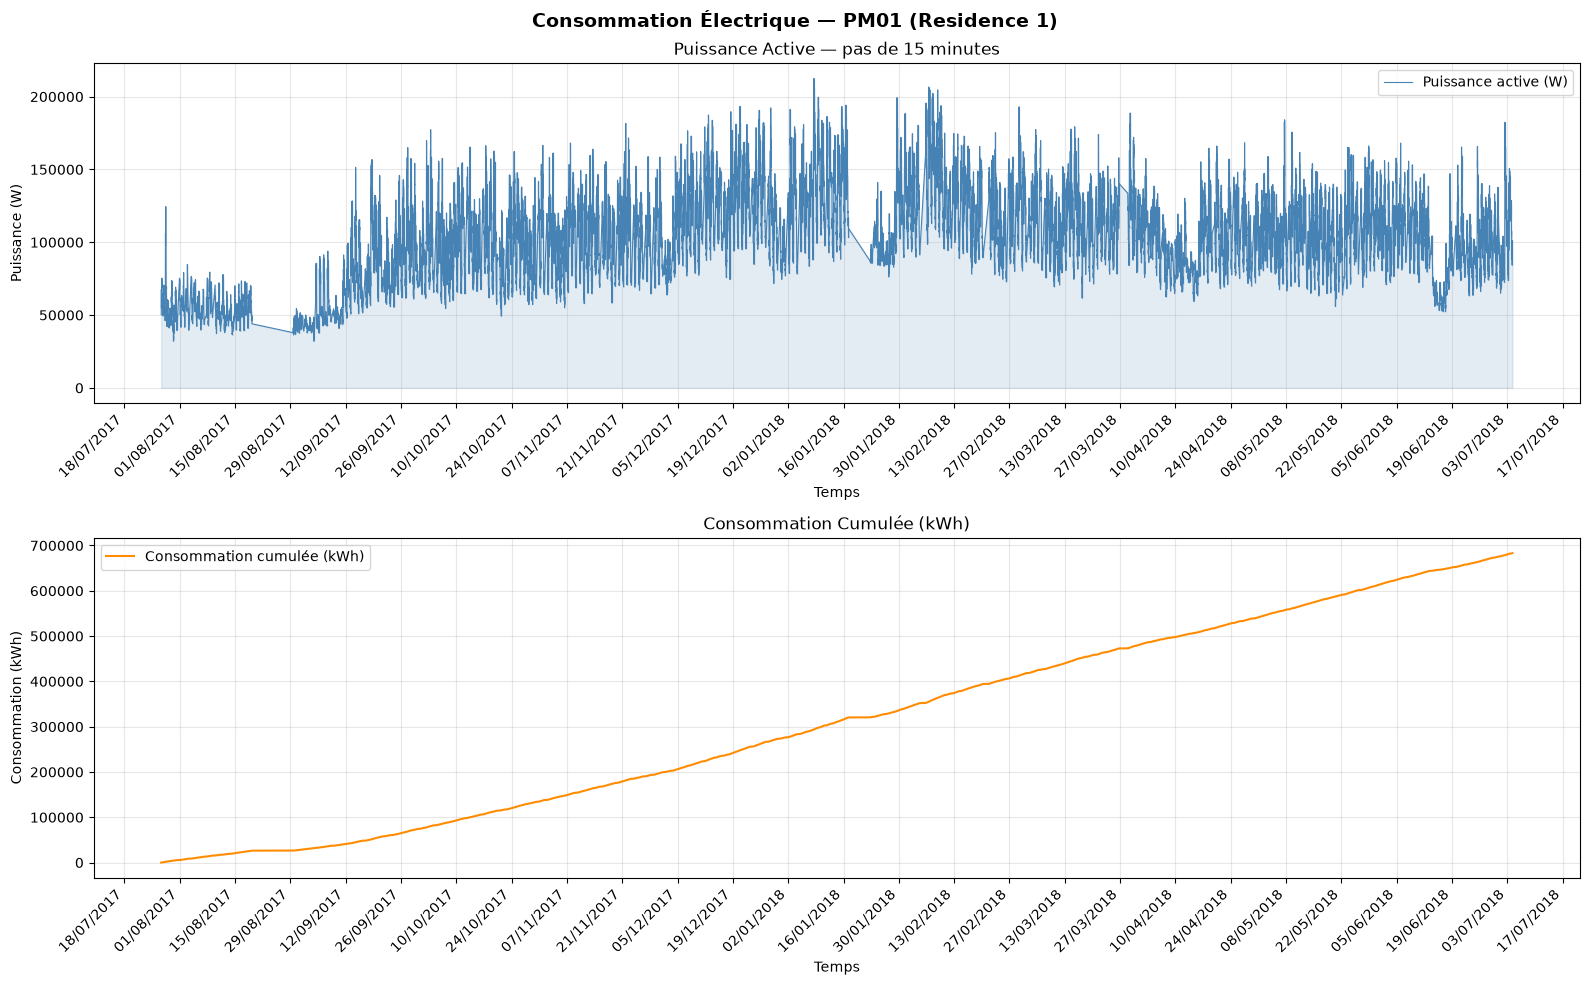

In [8]:
# Courbe 1 : Puissance active (W) + Consommation cumulée (kWh)
# Sauvegardé dans : reports/figures/pm01_power_consumption.png

plot_power_and_cumulative(df_clean)

---
## 4. Analyse Mensuelle & Facturation ONEE

In [9]:
# Calcul de la consommation mensuelle et estimation
# de la facture selon le tarif ONEE BT Résidentiel Maroc 2018
# Sauvegardé dans : data/outputs/pm01_monthly_billing.csv

df_billing = compute_monthly_billing(df_clean)
df_billing

[ANALYZE] Facturation mensuelle sauvegardée : C:\Users\CLOUD TECHNOLOGY\Downloads\SMART\PLATES-FORME SMART-ICT  ÉNERGIE\residence_energy_analysis\residence_energy_analysis\data\outputs\pm01_monthly_billing.csv

  RÉSUMÉ FACTURATION ONEE
  Consommation totale  : 683127.67 kWh
  Total factures       : 1341167.44 DH
  Facture moyenne/mois : 103166.73 DH



,year,month,month_label,energy_kwh,amount_ht_dh,vat_dh,fixed_charge_dh,total_ttc_dh
0,2017,7,Jul 2017,5474.75,9240.32,1293.65,9.0,10542.97
1,2017,8,Aug 2017,22983.62,39460.62,5524.49,9.0,44994.11
2,2017,9,Sep 2017,46522.50,80088.74,11212.42,9.0,91310.16
3,2017,10,Oct 2017,62490.65,107649.76,15070.97,9.0,122729.73
4,2017,11,Nov 2017,61506.42,105950.97,14833.14,9.0,120793.11
5,2017,12,Dec 2017,76748.56,132258.92,18516.25,9.0,150784.17
6,2018,1,Jan 2018,66144.73,113956.70,15953.94,9.0,129919.63
7,2018,2,Feb 2018,69437.02,119639.19,16749.49,9.0,136397.68
8,2018,3,Mar 2018,69837.24,120329.97,16846.20,9.0,137185.17
9,2018,4,Apr 2018,60399.27,104040.04,14565.61,9.0,118614.65


  [PLOT] Graphique sauvegardé : C:\Users\CLOUD TECHNOLOGY\Downloads\SMART\PLATES-FORME SMART-ICT  ÉNERGIE\residence_energy_analysis\residence_energy_analysis\reports\figures\pm01_monthly_billing.png


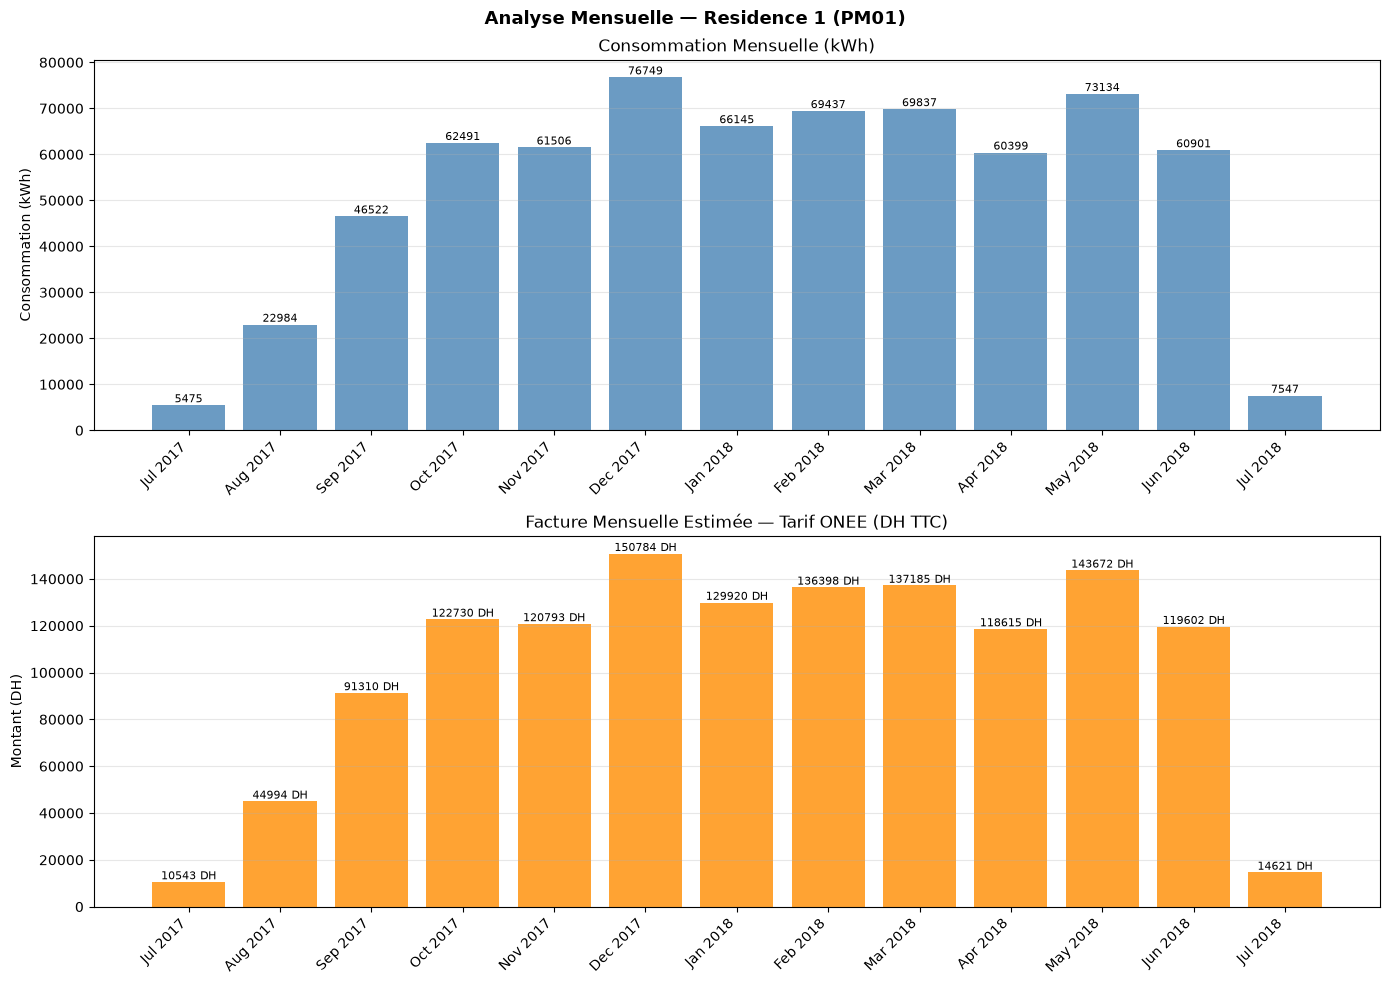

In [10]:
# Visualisation : barres consommation + barres facture
# Sauvegardé dans : reports/figures/pm01_monthly_billing.png

plot_monthly_billing(df_billing)

---
## 5. Analyse Ramadan 2018

Comparaison du profil horaire moyen de consommation :
- **Avant** Ramadan (même durée que Ramadan)
- **Pendant** Ramadan (17 mai → 14 juin 2018)
- **Après** Ramadan (même durée que Ramadan)

In [11]:
# Analyse des profils horaires autour de Ramadan
ramadan_profiles = analyze_ramadan(df_clean)


[ANALYZE] Analyse Ramadan 2018
  Période : 2018-05-17 → 2018-06-14
  [Avant Ramadan]
    Puissance moyenne  : 106476 W
    Consommation totale: 63592.88 kWh
    Heure de pointe    : 11h (126964 W)
  [Pendant Ramadan]
    Puissance moyenne  : 107624 W
    Consommation totale: 64278.60 kWh
    Heure de pointe    : 0h (136841 W)
  [Après Ramadan]
    Puissance moyenne  : 92523 W
    Consommation totale: 39067.63 kWh
    Heure de pointe    : 11h (110080 W)


  [PLOT] Graphique sauvegardé : C:\Users\CLOUD TECHNOLOGY\Downloads\SMART\PLATES-FORME SMART-ICT  ÉNERGIE\residence_energy_analysis\residence_energy_analysis\reports\figures\pm01_ramadan_analysis.png


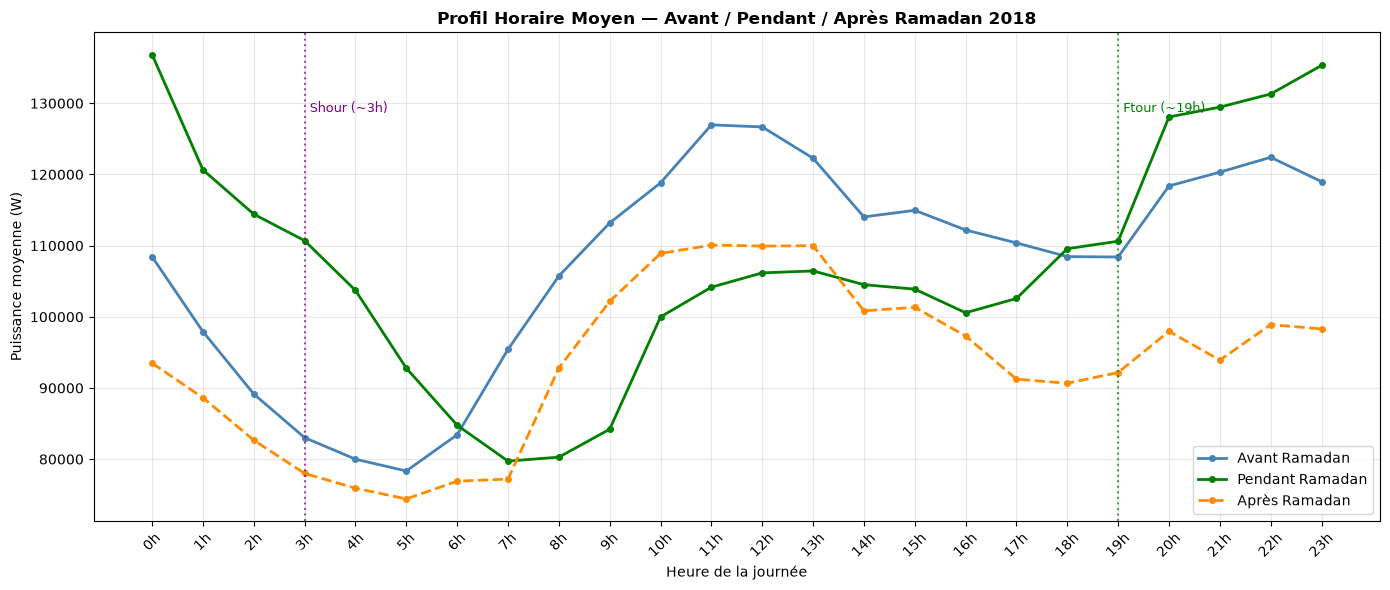

In [12]:
# Visualisation : profil horaire Avant / Pendant / Après Ramadan
# avec annotations Ftour (~19h) et Shour (~3h)
# Sauvegardé dans : reports/figures/pm01_ramadan_analysis.png

plot_ramadan_analysis(ramadan_profiles)


[ANALYZE] Profil hebdomadaire...

Jour          Conso moy (kWh)   Écart-type   Nb jours
------------------------------------------------------
  Lundi              2224.5        778.0         47
  Mardi              2168.8        819.8         47
  Mercredi           2046.8        895.3         48
  Jeudi              2154.9        779.0         47
  Vendredi           2101.9        759.1         47
  Samedi             1938.4        684.3         47
  Dimanche           1896.1        644.9         46

  Jour le + consommateur : Lundi
  Jour le - consommateur : Dimanche
  [PLOT] Graphique sauvegardé : C:\Users\CLOUD TECHNOLOGY\Downloads\SMART\PLATES-FORME SMART-ICT  ÉNERGIE\residence_energy_analysis\residence_energy_analysis\reports\figures\pm01_weekly_profile.png


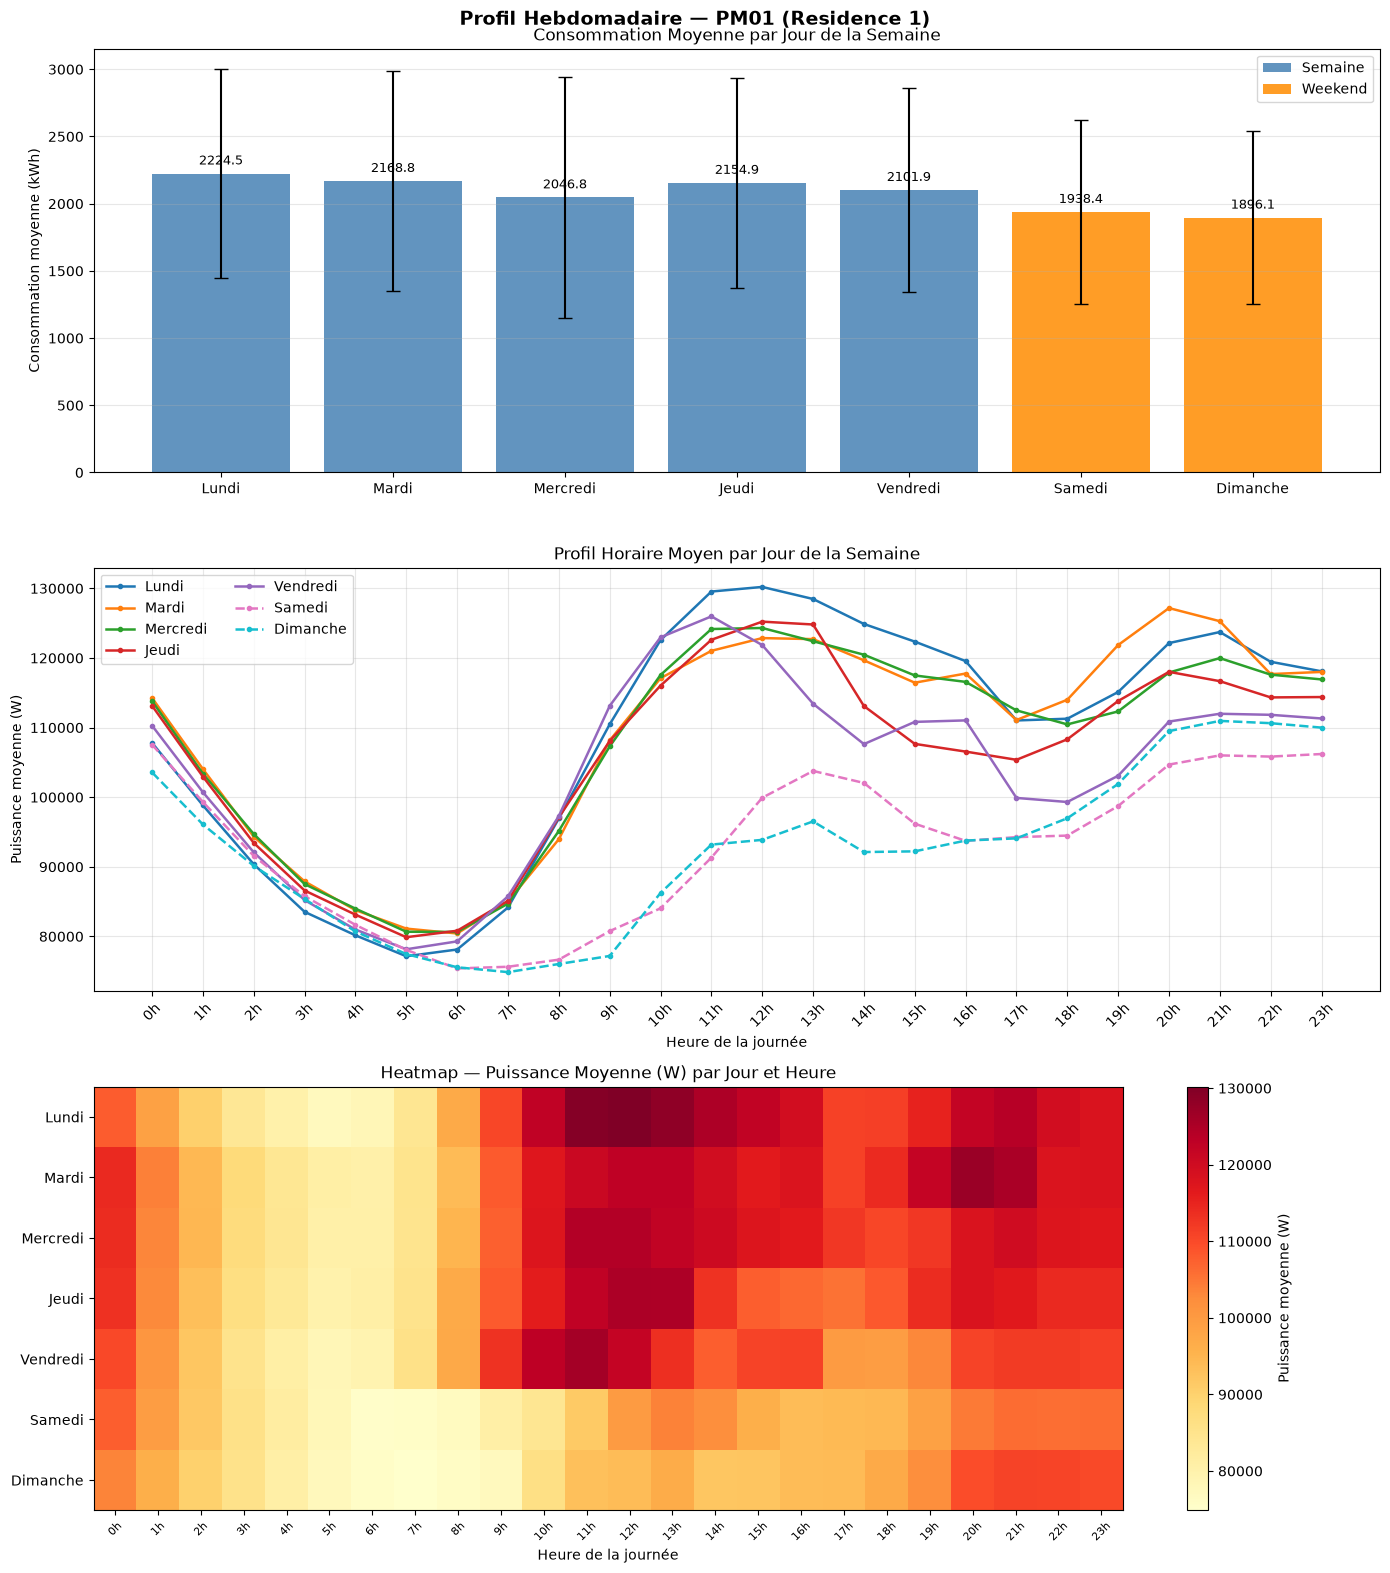

In [13]:
## 7. Profil Hebdomadaire

from src.analyzer   import analyze_weekly_profile
from src.visualizer import plot_weekly_profile

# Analyse
weekly_results = analyze_weekly_profile(df_clean)

# Visualisation : 3 graphiques (barres + courbes + heatmap)
plot_weekly_profile(weekly_results)